frames: train 72000, val 9600, test 9600
mean-speed baseline RMSE on test: 35.863 km/h
inputs: camera frames only (car_speed_km_h is used only as the training / evaluation label)



layer output shapes (batch = 1):
  input [I_t | dI(t,t-4) | dI(t-4,t-8)]  (1, 9, 160, 320)
  stem (4x4 conv s4 + LN)                (1, 96, 40, 80)


  stage 1 (3 blocks)                     (1, 96, 40, 80)
  downsample 1                           (1, 192, 20, 40)


  stage 2 (3 blocks)                     (1, 192, 20, 40)
  downsample 2                           (1, 384, 10, 20)


  stage 3 (9 blocks)                     (1, 384, 10, 20)
  downsample 3                           (1, 768, 5, 10)


  stage 4 (3 blocks)                     (1, 768, 5, 10)
  global avg pool                        (1, 768, 1, 1)
  layernorm + flatten                    (1, 768)
  head (dropout + linear)                (1, 1)
backbone = convnext_tiny, trainable parameters: 27,830,113

========== seed 0 ==========


... (91 outputs left out)

gru (seed 206) done at step 6000 in 36s, best val_rmse = 1.225 km/h (593,281 parameters)


gru (seed 207) done at step 6000 in 36s, best val_rmse = 1.271 km/h (593,281 parameters)


gru (seed 208) done at step 4500 in 28s, best val_rmse = 1.288 km/h (593,281 parameters)


gru (seed 209) done at step 6000 in 36s, best val_rmse = 1.223 km/h (593,281 parameters)
average of 10 grus: val_rmse = 1.213 km/h
[seed 2 cnn] smoothing = 5, val rmse = 2.717 km/h
[seed 2 cnn + gru] smoothing = 5, val rmse = 1.180 km/h

========== ensemble of 3 seeds ==========
[ensemble cnn only] smoothing = 5, val rmse = 2.647 km/h
[ensemble cnn + gru] smoothing = 5, val rmse = 1.181 km/h
per-segment test rmse: [1.87, 1.59, 1.59, 1.26, 0.98, 1.27, 1.78, 1.78]
OVERALL TEST RMSE (9600 frames, camera only): 1.543 km/h


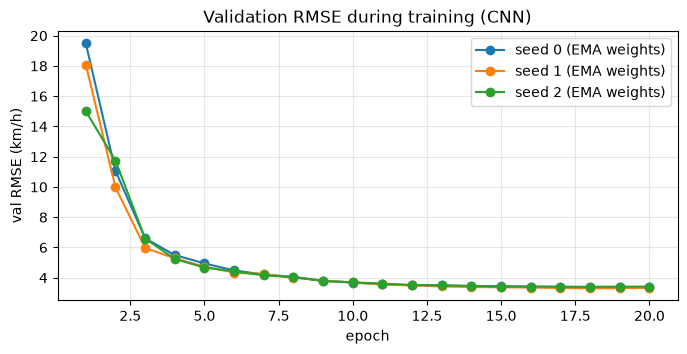

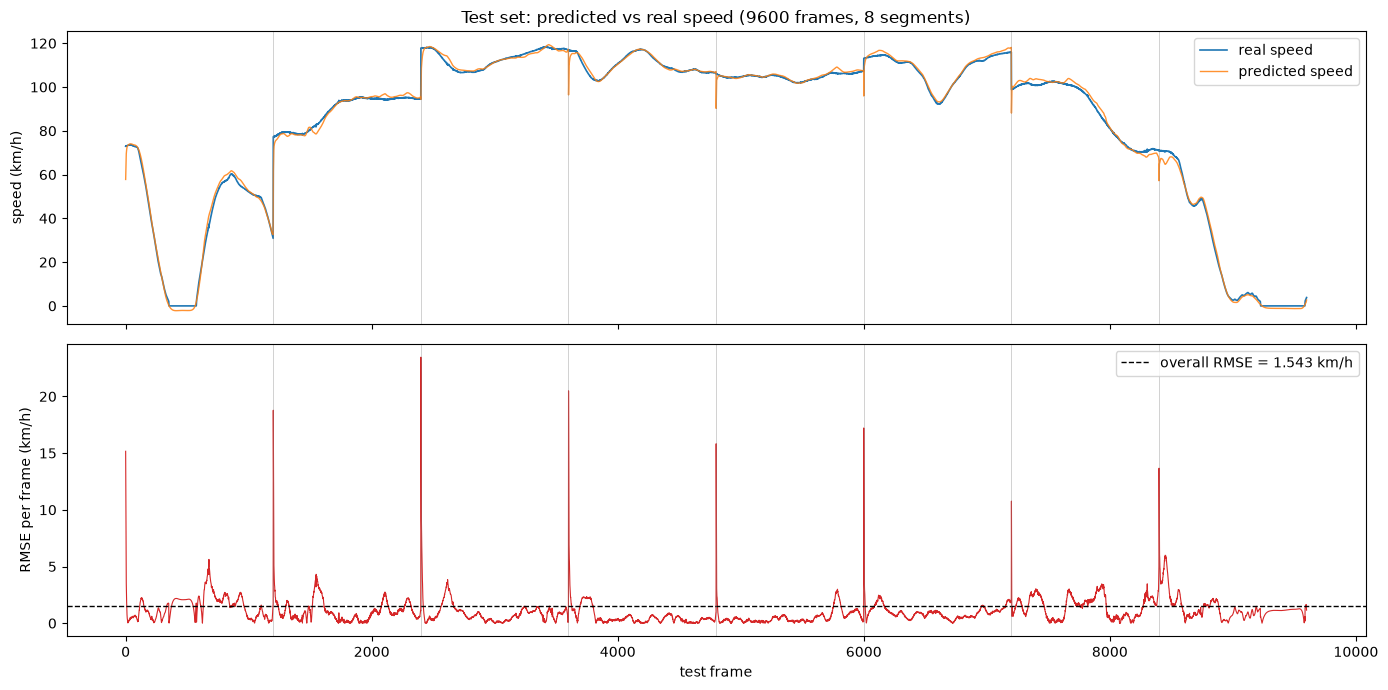

In [1]:
import os, time, copy, queue, threading
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
import matplotlib.pyplot as plt

torch.manual_seed(1234)
np.random.seed(1234)

data_root       = 'data/Comma_2k19_Driving_Dataset'
cache_dir       = 'cache_160x320'
splits          = {'train': 'Training', 'val': 'Validation', 'test': 'Testing'}
img_h, img_w    = 240, 320
crop_top        = 50
crop_bottom     = 210
crop_h          = crop_bottom - crop_top
frame_offsets   = [8, 4, 0]
speed_scale     = 100.0
batch_size      = 64
backbone        = 'convnext_tiny'
lr              = 1e-4
weight_decay    = 0.05
drop_path       = 0.2
ema_decay       = 0.999
diff_std        = 0.03
aug_scale       = 0.05
aug_shift       = 0.05
blur_prob       = 0.3
use_flip        = True
time_scale_prob = 0.8
time_scales     = [0.25, 0.5, 0.75, 1.25, 1.5, 2.0]
max_speed       = 160.0
still_prob      = 0.06
epochs          = 20
patience        = 4
smooth_grid     = [1, 5, 9, 15, 25, 41, 61, 81, 121, 161, 241]
gru_feat_passes = 2
gru_feat_noise  = 0.3
gru_feat_drop   = 0.2
gru_hidden      = 128
gru_window      = 400
gru_batch       = 32
gru_lr          = 5e-4
gru_steps       = 6000
gru_eval_every  = 100
gru_patience    = 20
gru_repeats     = 10
ensemble_seeds  = [0, 1, 2]
n_frames        = len(frame_offsets)
feat_dim        = 768
device          = 'cuda'

def load_img(path):
    with Image.open(path) as im:
        im.draft('RGB', (img_w, img_h))
        return np.asarray(im.convert('RGB').resize((img_w, img_h), Image.BILINEAR))[crop_top:crop_bottom]

def build_cache(split):
    base = os.path.join(data_root, splits[split])
    segs = sorted(os.listdir(base), key = lambda s: int(s.split('_')[-1]))
    paths, ys, seg_ids = [], [], []
    for i, s in enumerate(segs):
        df = pd.read_csv(os.path.join(base, s, 'labels.csv')).sort_values('frame')
        paths += [os.path.join(base, s, f) for f in df['filename']]
        ys.append(df['car_speed_km_h'].to_numpy(np.float32))
        seg_ids.append(np.full(len(df), i, np.int32))
    x = np.lib.format.open_memmap(f'{cache_dir}/{split}_x.npy', 'w+', np.uint8, (len(paths), crop_h, img_w, 3))
    with ThreadPoolExecutor(16) as ex:
        for k, img in enumerate(ex.map(load_img, paths, chunksize = 64)):
            x[k] = img
    x.flush()
    np.save(f'{cache_dir}/{split}_y.npy', np.concatenate(ys))
    np.save(f'{cache_dir}/{split}_seg.npy', np.concatenate(seg_ids))

os.makedirs(cache_dir, exist_ok = True)
for split in splits:
    if not os.path.exists(f'{cache_dir}/{split}_seg.npy'):
        t0 = time.time(); build_cache(split)
        print(f'cached {split} in {time.time() - t0:.0f}s')

class Pairs:
    def __init__(self, split):
        self.x = np.load(f'{cache_dir}/{split}_x.npy', mmap_mode = 'r')
        self.y = np.load(f'{cache_dir}/{split}_y.npy')
        self.seg = np.load(f'{cache_dir}/{split}_seg.npy')
        idx = np.arange(len(self.y))
        starts = np.r_[0, np.flatnonzero(np.diff(self.seg)) + 1]
        self.seg_start = starts[np.searchsorted(starts, idx, side = 'right') - 1]
        self.src = [np.maximum(idx - o, self.seg_start) for o in frame_offsets]

    def batches(self, bs, shuffle = False):
        order = np.random.permutation(len(self.y)) if shuffle else np.arange(len(self.y))
        n = len(order) // bs * bs if shuffle else len(order)
        chunks = [np.sort(order[i : i + bs]) if shuffle else order[i : i + bs] for i in range(0, n, bs)]
        q = queue.Queue(6)
        def work():
            for c in chunks:
                src, yv = [s[c] for s in self.src], self.y[c].copy()
                if shuffle:
                    # time-scale augmentation: frame gaps x s and speed label x s
                    k = len(c)
                    s = np.where(np.random.rand(k) < time_scale_prob, np.random.choice(time_scales, k), 1.0)
                    ok = (c - np.round(frame_offsets[0] * s).astype(int) >= self.seg_start[c]) & (yv * s <= max_speed)
                    s = np.where(ok, s, 1.0)
                    src = [np.maximum(c - np.round(o * s).astype(int), self.seg_start[c]) for o in frame_offsets]
                    yv = (yv * s).astype(np.float32)
                    # still samples: every frame = current frame, speed label 0
                    still = np.random.rand(k) < still_prob
                    src = [np.where(still, c, i) for i in src]
                    yv[still] = 0
                stack = np.concatenate([self.x[i] for i in src], axis = -1)
                q.put((torch.from_numpy(stack).pin_memory(), torch.from_numpy(yv / speed_scale)))
            q.put(None)
        threading.Thread(target = work, daemon = True).start()
        while (item := q.get()) is not None:
            yield item

train_ds, val_ds, test_ds = Pairs('train'), Pairs('val'), Pairs('test')
print(f'frames: train {len(train_ds.y)}, val {len(val_ds.y)}, test {len(test_ds.y)}')
print(f'mean-speed baseline RMSE on test: {np.sqrt(np.mean((test_ds.y - train_ds.y.mean()) ** 2)):.3f} km/h')
print('inputs: camera frames only (car_speed_km_h is used only as the training / evaluation label)')

mean = torch.tensor([0.485, 0.456, 0.406], device = device).view(1, 3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225], device = device).view(1, 3, 1, 1)

def to_input(xb, train):
    x = xb.to(device, non_blocking = True).permute(0, 3, 1, 2).float() / 255.0
    b = x.shape[0]
    if train:
        s = 1 + torch.empty(b, device = device).uniform_(-aug_scale, aug_scale)
        theta = torch.zeros(b, 2, 3, device = device)
        theta[:, 0, 0] = s; theta[:, 1, 1] = s
        theta[:, :, 2] = torch.empty(b, 2, device = device).uniform_(-aug_shift, aug_shift)
        grid = F.affine_grid(theta, x.shape, align_corners = False)
        x = F.grid_sample(x, grid, padding_mode = 'border', align_corners = False)
        x = x.view(b, n_frames, 3, *x.shape[2:])
        bright = torch.empty(b, 1, 1, 1, 1, device = device).uniform_(0.7, 1.3)
        contrast = torch.empty(b, 1, 1, 1, 1, device = device).uniform_(0.7, 1.3)
        gain = torch.empty(b, 1, 3, 1, 1, device = device).uniform_(0.9, 1.1)
        m = x.mean(dim = (1, 2, 3, 4), keepdim = True)
        x = (((x - m) * contrast + m) * bright * gain).clamp(0, 1).view(b, 3 * n_frames, *x.shape[3:])
        if torch.rand(1).item() < blur_prob:
            x = torchvision.transforms.functional.gaussian_blur(x, 5, float(np.random.uniform(0.5, 1.5)))
        if use_flip:
            flip = torch.rand(b, device = device) < 0.5
            x[flip] = x[flip].flip(-1)
    f = x.view(b, n_frames, 3, *x.shape[2:])
    cur = (f[:, -1] - mean) / std
    diffs = [(f[:, i + 1] - f[:, i]) / diff_std for i in reversed(range(n_frames - 1))]
    return torch.cat([cur] + diffs, 1).contiguous(memory_format = torch.channels_last)

def embed(m, x):
    return torch.flatten(m.classifier[1](m.classifier[0](m.avgpool(m.features(x)))), 1)

def create_model():
    m = torchvision.models.convnext_tiny(weights = torchvision.models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1,
                                         stochastic_depth_prob = drop_path)
    old = m.features[0][0]
    m.features[0][0] = nn.Conv2d(3 * n_frames, 96, 4, 4)
    m.features[0][0].weight.data = torch.cat([old.weight.data] + [old.weight.data * 0.5] * (n_frames - 1), 1)
    m.features[0][0].bias.data = old.bias.data.clone()
    m.classifier[2] = nn.Sequential(nn.Dropout(0.3), nn.Linear(feat_dim, 1))
    return m.to(device).to(memory_format = torch.channels_last)

@torch.no_grad()
def predict(model, ds):
    model.eval()
    out = []
    for xb, _ in ds.batches(256):
        with torch.autocast('cuda', dtype = torch.bfloat16):
            out.append(model(to_input(xb, False)).float().squeeze(1).cpu())
    return torch.cat(out).numpy() * speed_scale

def smooth(pred, seg, k):
    if k <= 1:
        return pred
    out = np.empty_like(pred)
    for s in np.unique(seg):
        m = seg == s
        out[m] = np.convolve(np.pad(pred[m], k // 2, mode = 'edge'), np.ones(k) / k, mode = 'valid')
    return out

def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

model = create_model()
print('\nlayer output shapes (batch = 1):')
x = torch.zeros(1, 3 * n_frames, crop_h, img_w, device = device)
print(f'  {"input [I_t | dI(t,t-4) | dI(t-4,t-8)]":38s} {tuple(x.shape)}')
model.eval()
with torch.no_grad():
    names = ['stem (4x4 conv s4 + LN)', 'stage 1 (3 blocks)', 'downsample 1', 'stage 2 (3 blocks)',
             'downsample 2', 'stage 3 (9 blocks)', 'downsample 3', 'stage 4 (3 blocks)']
    for name, layer in zip(names, model.features):
        x = layer(x)
        print(f'  {name:38s} {tuple(x.shape)}')
    x = model.avgpool(x)
    print(f'  {"global avg pool":38s} {tuple(x.shape)}')
    x = model.classifier[1](model.classifier[0](x))
    print(f'  {"layernorm + flatten":38s} {tuple(x.shape)}')
    print(f'  {"head (dropout + linear)":38s} {tuple(model.classifier[2](x).shape)}')
print(f'backbone = {backbone}, trainable parameters: {sum(p.numel() for p in model.parameters()):,}')
del model

def train_cnn(seed):
    torch.manual_seed(seed); np.random.seed(seed)
    model = create_model()
    ema = copy.deepcopy(model)
    for p in ema.parameters():
        p.requires_grad_(False)
    opt = torch.optim.AdamW(model.parameters(), lr = lr, weight_decay = weight_decay)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps = epochs * (len(train_ds.y) // batch_size), pct_start = 0.1)
    best_val_rmse, best_weights, no_improve, hist_val = float('inf'), None, 0, []
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        tot, n = 0.0, 0
        for xb, yb in train_ds.batches(batch_size, shuffle = True):
            yb = yb.to(device, non_blocking = True).float()
            with torch.autocast('cuda', dtype = torch.bfloat16):
                pred = model(to_input(xb, True)).float().squeeze(1)
            loss = F.smooth_l1_loss(pred, yb, beta = 0.05)
            opt.zero_grad(set_to_none = True)
            loss.backward()
            opt.step(); sched.step()
            with torch.no_grad():
                for e, m in zip(ema.state_dict().values(), model.state_dict().values()):
                    if e.dtype.is_floating_point:
                        e.lerp_(m, 1 - ema_decay)
                    else:
                        e.copy_(m)
            tot += loss.item() * len(yb); n += len(yb)
        raw_rmse = rmse(predict(model, val_ds), val_ds.y)
        val_rmse = rmse(predict(ema, val_ds), val_ds.y)
        hist_val.append((raw_rmse, val_rmse))
        msg = f'epoch {ep + 1}/{epochs}: train_loss = {tot / n:.4f}  val_rmse raw = {raw_rmse:.3f}  ema = {val_rmse:.3f} km/h'
        if val_rmse < best_val_rmse - 1e-3:
            best_val_rmse = val_rmse; no_improve = 0
            best_weights = {k: v.detach().clone() for k, v in ema.state_dict().items()}
            print(f'{msg}  <- new best')
        else:
            no_improve += 1
            print(f'{msg}  (no improvement {no_improve}/{patience})')
            if no_improve >= patience:
                print(f'early stopping at epoch {ep + 1}')
                break
    print(f'cnn done in {(time.time() - t0) / 60:.1f} min, best val_rmse = {best_val_rmse:.3f} km/h')
    model.load_state_dict(best_weights)
    return model, hist_val

@torch.no_grad()
def extract(model, ds, aug, flip = False):
    model.eval()
    out = []
    for xb, _ in ds.batches(256):
        with torch.autocast('cuda', dtype = torch.bfloat16):
            x = to_input(xb, aug)
            out.append(embed(model, x.flip(-1) if flip else x).float())
    return torch.cat(out)

class SpeedGRU(nn.Module):
    def __init__(self):
        super().__init__()
        self.drop = nn.Dropout(gru_feat_drop)
        self.inp = nn.Sequential(nn.Linear(feat_dim, gru_hidden), nn.GELU())
        self.gru = nn.GRU(gru_hidden, gru_hidden, num_layers = 2, batch_first = True, bidirectional = True, dropout = 0.2)
        self.out = nn.Linear(2 * gru_hidden, 1)

    def forward(self, f):
        return self.out(self.gru(self.inp(self.drop(f)))[0]).squeeze(-1)

@torch.no_grad()
def gru_predict(gru, seqs):
    gru.eval()
    return np.mean([gru(seq).flatten().cpu().numpy() for seq in seqs], 0) * speed_scale

seg_len = 1200
y_tr = torch.tensor(train_ds.y / speed_scale, device = device).view(-1, seg_len)

def train_gru(model, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    t0 = time.time()
    feat_tr = [extract(model, train_ds, True) for _ in range(gru_feat_passes)]
    f_mean, f_std = feat_tr[0].mean(0), feat_tr[0].std(0) + 1e-6
    norm = lambda f: ((f - f_mean) / f_std).view(-1, seg_len, feat_dim)
    seq_tr = [norm(f) for f in feat_tr]
    # flip test-time augmentation: features of the original and the mirrored frames
    seq_va = [norm(extract(model, val_ds, False, flip)) for flip in (False, True)]
    seq_te = [norm(extract(model, test_ds, False, flip)) for flip in (False, True)]
    print(f'extracted {feat_dim}-d cnn features in {time.time() - t0:.0f}s ({gru_feat_passes} augmented passes on train, flip tta on val / test)')
    preds = [fit_gru(seq_tr, seq_va, seq_te, seed * 100 + r) for r in range(gru_repeats)]
    val_pred, test_pred = np.mean([p[0] for p in preds], 0), np.mean([p[1] for p in preds], 0)
    print(f'average of {gru_repeats} grus: val_rmse = {rmse(val_pred, val_ds.y):.3f} km/h')
    return val_pred, test_pred

def fit_gru(seq_tr, seq_va, seq_te, gru_seed):
    torch.manual_seed(gru_seed); np.random.seed(gru_seed)
    t0 = time.time()
    gru = SpeedGRU().to(device)
    gru_opt = torch.optim.AdamW(gru.parameters(), lr = gru_lr, weight_decay = 1e-2)
    gru_sched = torch.optim.lr_scheduler.CosineAnnealingLR(gru_opt, gru_steps)
    best_gru_rmse, best_gru_weights, gru_no_improve = float('inf'), None, 0
    for step in range(1, gru_steps + 1):
        gru.train()
        s = torch.randint(0, y_tr.shape[0], (gru_batch,), device = device)
        st = torch.randint(0, seg_len - gru_window + 1, (gru_batch,), device = device)
        idx = st[:, None] + torch.arange(gru_window, device = device)
        fb = seq_tr[np.random.randint(gru_feat_passes)][s[:, None], idx]
        fb = fb + gru_feat_noise * torch.randn_like(fb)
        loss = F.mse_loss(gru(fb), y_tr[s[:, None], idx])
        gru_opt.zero_grad(set_to_none = True)
        loss.backward()
        nn.utils.clip_grad_norm_(gru.parameters(), 1.0)
        gru_opt.step(); gru_sched.step()
        if step % gru_eval_every == 0:
            v = rmse(gru_predict(gru, seq_va), val_ds.y)
            if v < best_gru_rmse - 1e-3:
                best_gru_rmse = v; gru_no_improve = 0
                best_gru_weights = {k: t.detach().clone() for k, t in gru.state_dict().items()}
            else:
                gru_no_improve += 1
                if gru_no_improve >= gru_patience:
                    break
    print(f'gru (seed {gru_seed}) done at step {step} in {time.time() - t0:.0f}s, best val_rmse = {best_gru_rmse:.3f} km/h '
          f'({sum(p.numel() for p in gru.parameters()):,} parameters)')
    gru.load_state_dict(best_gru_weights)
    return gru_predict(gru, seq_va), gru_predict(gru, seq_te)

def pick_smooth(val_pred, tag):
    scores = {k: rmse(smooth(val_pred, val_ds.seg, k), val_ds.y) for k in smooth_grid}
    k = min(scores, key = scores.get)
    print(f'{tag} smoothing = {k}, val rmse = {scores[k]:.3f} km/h')
    return k, scores[k]

cnn_vals, cnn_tests, gru_vals, gru_tests, hists = [], [], [], [], []
for seed in ensemble_seeds:
    print(f'\n========== seed {seed} ==========')
    model, hist_val = train_cnn(seed)
    hists.append(hist_val)
    cnn_vals.append(predict(model, val_ds)); cnn_tests.append(predict(model, test_ds))
    gv, gt = train_gru(model, seed)
    gru_vals.append(gv); gru_tests.append(gt)
    pick_smooth(cnn_vals[-1], f'[seed {seed} cnn]')
    pick_smooth(gru_vals[-1], f'[seed {seed} cnn + gru]')
    del model; torch.cuda.empty_cache()

print(f'\n========== ensemble of {len(ensemble_seeds)} seeds ==========')
pick_smooth(np.mean(cnn_vals, 0), '[ensemble cnn only]')
k, _ = pick_smooth(np.mean(gru_vals, 0), '[ensemble cnn + gru]')
test_pred = smooth(np.mean(gru_tests, 0), test_ds.seg, k)
seg_rmse = [rmse(test_pred[test_ds.seg == s], test_ds.y[test_ds.seg == s]) for s in range(8)]
print(f'per-segment test rmse: {[round(r, 2) for r in seg_rmse]}')
overall_rmse = rmse(test_pred, test_ds.y)
print(f'OVERALL TEST RMSE ({len(test_ds.y)} frames, camera only): {overall_rmse:.3f} km/h')

frame_rmse = np.abs(test_pred - test_ds.y)
pd.DataFrame({'segment': test_ds.seg, 'real_kmh': test_ds.y, 'pred_kmh': test_pred, 'frame_rmse': frame_rmse}
             ).to_csv('test_predictions.csv', index_label = 'frame')

plt.figure(figsize = (8, 3.5))
for seed, h in zip(ensemble_seeds, hists):
    plt.plot(range(1, len(h) + 1), [v[1] for v in h], 'o-', label = f'seed {seed} (EMA weights)')
plt.xlabel('epoch'); plt.ylabel('val RMSE (km/h)'); plt.title('Validation RMSE during training (CNN)')
plt.legend(); plt.grid(alpha = 0.3); plt.show()

frames = np.arange(len(test_ds.y))
bounds = np.flatnonzero(np.diff(test_ds.seg)) + 0.5
fig, ax = plt.subplots(2, 1, figsize = (14, 7), sharex = True)
ax[0].plot(frames, test_ds.y, lw = 1.2, label = 'real speed')
ax[0].plot(frames, test_pred, lw = 1.0, alpha = 0.85, label = 'predicted speed')
ax[0].set_ylabel('speed (km/h)'); ax[0].legend(loc = 'upper right')
ax[0].set_title(f'Test set: predicted vs real speed ({len(test_ds.y)} frames, 8 segments)')
ax[1].plot(frames, frame_rmse, lw = 0.8, color = 'tab:red')
ax[1].axhline(overall_rmse, color = 'k', ls = '--', lw = 1, label = f'overall RMSE = {overall_rmse:.3f} km/h')
ax[1].set_ylabel('RMSE per frame (km/h)'); ax[1].set_xlabel('test frame'); ax[1].legend(loc = 'upper right')
for a in ax:
    for b in bounds:
        a.axvline(b, color = 'gray', lw = 0.5, alpha = 0.5)
fig.tight_layout(); fig.savefig('test_speed_and_rmse.png', dpi = 150); plt.show()